# Pakistan Used Car Data

## Part A: Data Understanding

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("pakwheels_used_car_data_v02.csv")
df.head()

,addref,city,assembly,body,make,model,year,engine,transmission,fuel,color,registered,mileage,price
0,7943732,Peshawar,NaN,Sedan,Toyota,Corolla,2013.0,1300.0,Manual,Petrol,Silver Metallic,Lahore,145000,2870000.0
1,7730314,Lahore,NaN,Sedan,Honda,City,2000.0,1300.0,Manual,Petrol,Blue,Lahore,230000,995000.0
2,7943737,Lahore,NaN,Sedan,Toyota,Yaris,2021.0,1300.0,Manual,Petrol,Super White,Punjab,60500,3585000.0
3,7943733,Lahore,NaN,Hatchback,Suzuki,Swift,2017.0,1300.0,Manual,Petrol,Grey,Islamabad,87000,2250000.0
4,7923484,Lahore,NaN,Sedan,Honda,Civic,2017.0,1800.0,Automatic,Petrol,Grey,Lahore,86000,4850000.0


In [2]:
print("Shape:", df.shape)
print("Dataset Information:")
df.info()
print("Summary Statistics:")
df.describe()

Shape: (77878, 14)
Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 77878 entries, 0 to 77877
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   addref        77878 non-null  int64  
 1   city          77878 non-null  str    
 2   assembly      24189 non-null  str    
 3   body          68974 non-null  str    
 4   make          77878 non-null  str    
 5   model         77878 non-null  str    
 6   year          73099 non-null  float64
 7   engine        77875 non-null  float64
 8   transmission  77878 non-null  str    
 9   fuel          76972 non-null  str    
 10  color         76398 non-null  str    
 11  registered    77878 non-null  str    
 12  mileage       77878 non-null  int64  
 13  price         77295 non-null  float64
dtypes: float64(3), int64(2), str(9)
memory usage: 8.3 MB
Summary Statistics:


,addref,year,engine,mileage,price
count,7.787800e+04,73099.000000,77875.000000,77878.000000,7.729500e+04
mean,7.809878e+06,2012.812610,1408.072550,91109.192750,3.883232e+06
std,2.599523e+05,7.516685,704.459947,89275.336173,5.759480e+06
min,2.748970e+05,1990.000000,3.000000,1.000000,1.100000e+05
25%,7.805760e+06,2007.000000,1000.000000,34000.000000,1.450000e+06
50%,7.865805e+06,2015.000000,1300.000000,80000.000000,2.700000e+06
75%,7.910334e+06,2019.000000,1600.000000,123456.000000,4.500000e+06
max,7.943741e+06,2022.000000,15000.000000,1000000.000000,5.290000e+08


**Interpretation:** The dataset contains 77,878 used-car listings from Pakistan, with 14 columns describing different vehicle characteristics. Each row represents one car listing on PakWheels. The dataset includes information such as car brand, model, manufacturing year, mileage, engine capacity, fuel type, transmission, city, and asking price. It contains both numerical and categorical variables, making it suitable for analyzing the Pakistani used-car market. The analysis will focus on identifying pricing patterns and understanding how vehicle characteristics relate to asking prices.

## Part B: Data Cleaning

In [3]:
print("Missing values:")
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

Missing values:
addref              0
city                0
assembly        53689
body             8904
make                0
model               0
year             4779
engine              3
transmission        0
fuel              906
color            1480
registered          0
mileage             0
price             583
dtype: int64
Duplicates: 0


In [4]:
df["assembly"] = df["assembly"].fillna("Unknown")
df["body"] = df["body"].fillna("Unknown")
df["fuel"] = df["fuel"].fillna("Unknown")
df["color"] = df["color"].fillna("Unknown")
df = df.dropna(subset=["year", "engine", "price"])
df.isnull().sum()

addref          0
city            0
assembly        0
body            0
make            0
model           0
year            0
engine          0
transmission    0
fuel            0
color           0
registered      0
mileage         0
price           0
dtype: int64

In [5]:
df["year"] = df["year"].astype(int)
df["engine"] = df["engine"].astype(int)
df.dtypes

addref            int64
city                str
assembly            str
body                str
make                str
model               str
year              int64
engine            int64
transmission        str
fuel                str
color               str
registered          str
mileage           int64
price           float64
dtype: object

In [6]:
df = df.drop_duplicates()
df.shape

(72670, 14)

In [7]:
df[["year", "engine", "mileage", "price"]].describe()

,year,engine,mileage,price
count,72670.000000,72670.000000,72670.000000,7.267000e+04
mean,2012.785785,1393.851865,93197.195225,3.798989e+06
std,7.522076,692.747572,86095.292150,5.525937e+06
min,1990.000000,20.000000,1.000000,1.100000e+05
25%,2007.000000,1000.000000,39000.000000,1.495000e+06
50%,2015.000000,1300.000000,82000.000000,2.700000e+06
75%,2019.000000,1600.000000,123456.000000,4.450000e+06
max,2022.000000,15000.000000,1000000.000000,5.290000e+08


In [8]:
df = df[df["year"].between(1990, 2022)]
df = df[df["engine"] >= 600]
df = df[df["mileage"] >= 0]
df = df[df["price"] > 0]
df.shape

(72529, 14)

In [9]:
print("Missing values:")
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
df.shape

Missing values:
addref          0
city            0
assembly        0
body            0
make            0
model           0
year            0
engine          0
transmission    0
fuel            0
color           0
registered      0
mileage         0
price           0
dtype: int64
Duplicates: 0


(72529, 14)

In [10]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.DataFrame'>
Index: 72529 entries, 0 to 77877
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   addref        72529 non-null  int64  
 1   city          72529 non-null  str    
 2   assembly      72529 non-null  str    
 3   body          72529 non-null  str    
 4   make          72529 non-null  str    
 5   model         72529 non-null  str    
 6   year          72529 non-null  int64  
 7   engine        72529 non-null  int64  
 8   transmission  72529 non-null  str    
 9   fuel          72529 non-null  str    
 10  color         72529 non-null  str    
 11  registered    72529 non-null  str    
 12  mileage       72529 non-null  int64  
 13  price         72529 non-null  float64
dtypes: float64(1), int64(4), str(9)
memory usage: 8.3 MB


In [11]:
cleaning_log = pd.DataFrame({
    "Problem found": [
        "Missing assembly values",
        "Missing body, fuel, and color values",
        "Missing year, engine, and price values",
        "Incorrect year and engine data types",
        "Duplicate rows checked",
        "Invalid engine capacities",
        "Invalid numerical values checked"
    ],
    "Action taken": [
        "Filled with Unknown",
        "Filled with Unknown",
        "Removed affected rows",
        "Converted to integers",
        "Checked and removed duplicates",
        "Removed engine values below 600 cc",
        "Checked year, mileage, and price ranges"
    ],
    "Reason": [
        "Assembly information was unavailable",
        "Preserve records with missing categories",
        "These values are essential for analysis",
        "These columns represent whole numbers",
        "Avoid repeated records",
        "Exclude unrealistic engine capacities",
        "Ensure numerical values are reasonable"
    ]
})

cleaning_log

,Problem found,Action taken,Reason
0,Missing assembly values,Filled with Unknown,Assembly information was unavailable
1,"Missing body, fuel, and color values",Filled with Unknown,Preserve records with missing categories
2,"Missing year, engine, and price values",Removed affected rows,These values are essential for analysis
3,Incorrect year and engine data types,Converted to integers,These columns represent whole numbers
4,Duplicate rows checked,Checked and removed duplicates,Avoid repeated records
5,Invalid engine capacities,Removed engine values below 600 cc,Exclude unrealistic engine capacities
6,Invalid numerical values checked,"Checked year, mileage, and price ranges",Ensure numerical values are reasonable


## Part C: Feature Engineering

In [12]:
df["vehicle_age"] = 2023 - df["year"]
df["price_lakhs"] = df["price"] / 100000
df["mileage_category"] = pd.cut(
    df["mileage"],
    bins=[-1, 50000, 100000, float("inf")],
    labels=["Low", "Medium", "High"]
)
df[["year", "vehicle_age", "price", "price_lakhs", "mileage", "mileage_category"]].head()

,year,vehicle_age,price,price_lakhs,mileage,mileage_category
0,2013,10,2870000.0,28.70,145000,High
1,2000,23,995000.0,9.95,230000,High
2,2021,2,3585000.0,35.85,60500,Medium
3,2017,6,2250000.0,22.50,87000,Medium
4,2017,6,4850000.0,48.50,86000,Medium


## Part D: Visualizations
### 1. Chart 1: Trend over time

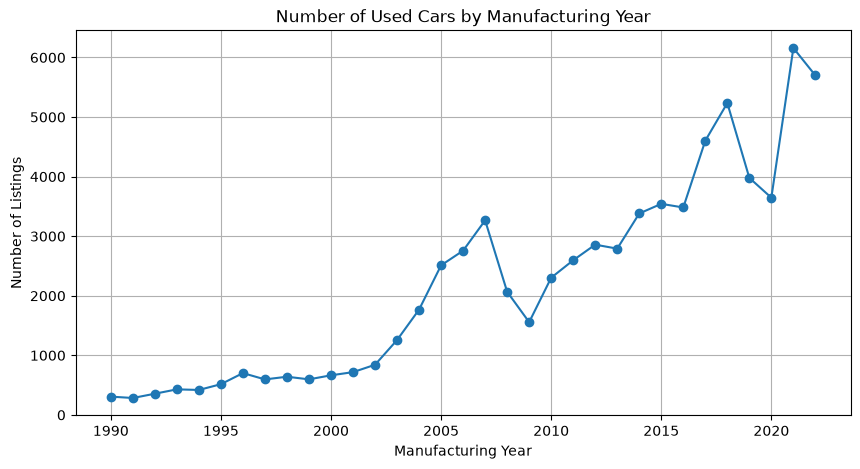

In [13]:
year_counts = df.groupby("year").size()

plt.figure(figsize=(10, 5))
plt.plot(year_counts.index, year_counts.values, marker="o")
plt.title("Number of Used Cars by Manufacturing Year")
plt.xlabel("Manufacturing Year")
plt.ylabel("Number of Listings")
plt.grid(True)
plt.show()

In [14]:
print(year_counts.sort_values(ascending=False))

year
2021    6159
2022    5698
2018    5235
2017    4603
2019    3979
2020    3646
2015    3543
2016    3482
2014    3381
2007    3266
2012    2858
2013    2791
2006    2757
2011    2596
2005    2511
2010    2303
2008    2067
2004    1768
2009    1557
2003    1257
2002     842
2001     718
1996     702
2000     665
1998     641
1999     597
1997     596
1995     516
1993     429
1994     419
1992     356
1990     307
1991     284
dtype: int64


**Interpretation:**
- **What?** Vehicles manufactured in 2021 have the most listings (6,159), followed by 2022 (5,698) and 2018 (5,235).
- **So what?** This shows that relatively recent model years have a strong presence in the dataset.
- **Now what?** Dealerships should consider these model years when planning inventory, while also checking prices and customer demand.

### 2. Chart 2: Category comparison

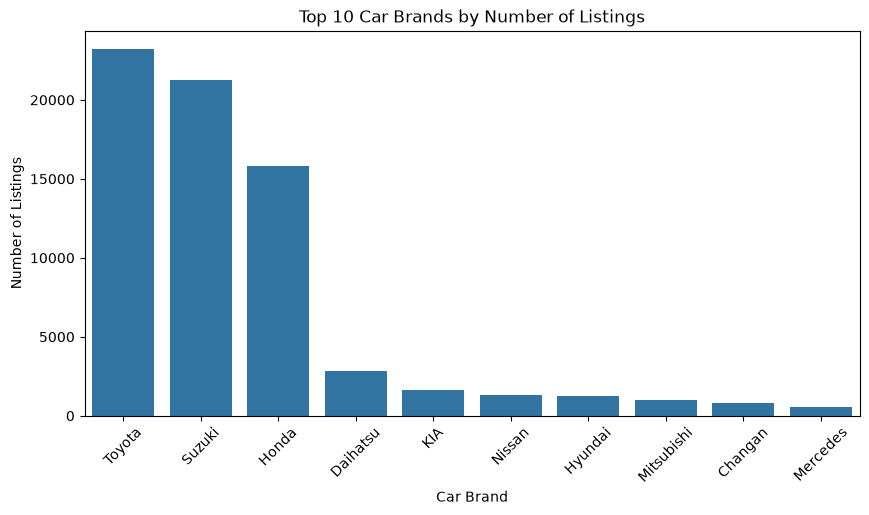

In [15]:
top_makes = df["make"].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_makes.index, y=top_makes.values)
plt.title("Top 10 Car Brands by Number of Listings")
plt.xlabel("Car Brand")
plt.ylabel("Number of Listings")
plt.xticks(rotation=45)
plt.show()

In [16]:
print(top_makes)

make
Toyota        23217
Suzuki        21258
Honda         15789
Daihatsu       2855
KIA            1606
Nissan         1337
Hyundai        1236
Mitsubishi     1001
Changan         823
Mercedes        541
Name: count, dtype: int64


**Interpretation:**
- **What?** Toyota has the highest number of listings (23,217), followed by Suzuki (21,258) and Honda (15,789).
- **So what?** These three brands dominate the dataset and represent a large share of Pakistan's listed used-car market.
- **Now what?** Dealerships should focus on monitoring these brands when planning inventory and pricing strategies.

### Chart 3: Distribution

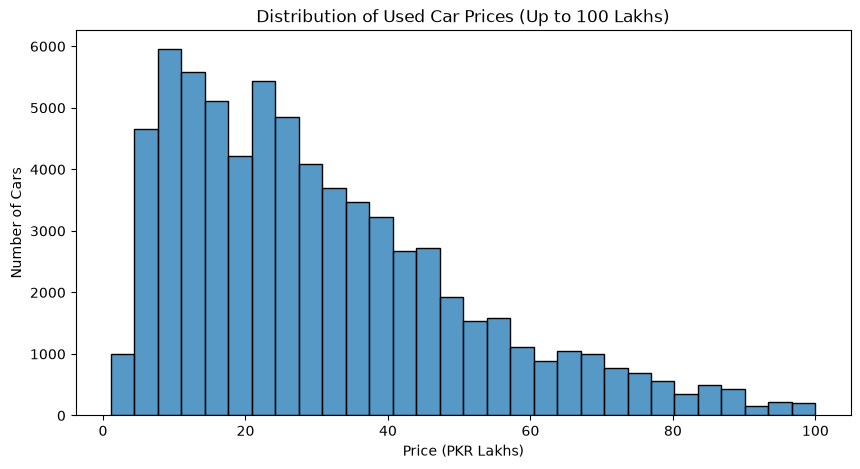

In [30]:
plt.figure(figsize=(10, 5))
sns.histplot(df[df["price_lakhs"] <= 100]["price_lakhs"], bins=30)
plt.title("Distribution of Used Car Prices (Up to 100 Lakhs)")
plt.xlabel("Price (PKR Lakhs)")
plt.ylabel("Number of Cars")
plt.show()

**Interpretation:**
- **What?** Among the 69,652 cars priced up to PKR 100 lakhs, the median asking price is PKR 26 lakh, with half of the listings priced between approximately PKR 14.5 and 42 lakh.
- **So what?** This shows that a large share of listings falls within relatively affordable and mid-range price segments.
- **Now what?** Dealerships should consider offering vehicles across these price ranges to accommodate different customer budgets.

### Chart 4: Relationship

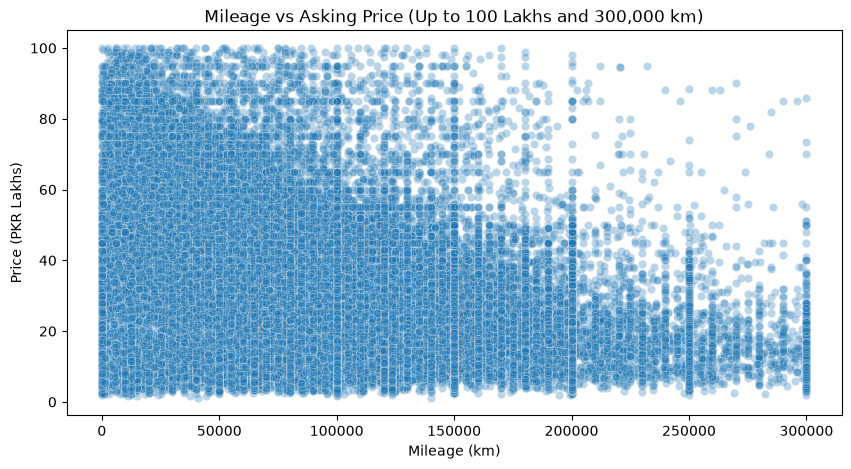

In [18]:
scatter_df = df[(df["price_lakhs"] <= 100) & (df["mileage"] <= 300000)]

plt.figure(figsize=(10, 5))
sns.scatterplot(data=scatter_df, x="mileage", y="price_lakhs", alpha=0.3)
plt.title("Mileage vs Asking Price (Up to 100 Lakhs and 300,000 km)")
plt.xlabel("Mileage (km)")
plt.ylabel("Price (PKR Lakhs)")
plt.show()

In [19]:
scatter_df["mileage"].corr(scatter_df["price_lakhs"])

np.float64(-0.27963701408086317)

**Interpretation:**
- **What?** The scatter plot shows a negative relationship between mileage and asking price, with a correlation of approximately -0.28 for cars priced up to PKR 100 lakhs and driven up to 300,000 km.
- **So what?** Higher-mileage vehicles generally tend to have lower asking prices, although there is considerable variation.
- **Now what?** Dealerships should consider mileage alongside age, brand, and vehicle condition when determining prices.

### Chart 5: Correlation

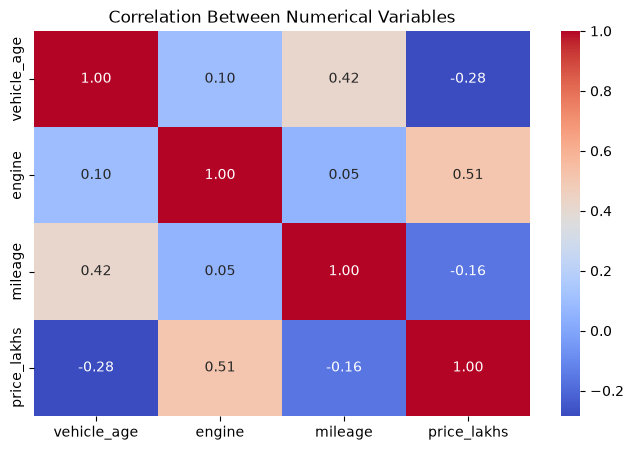

In [20]:
corr = df[["vehicle_age", "engine", "mileage", "price_lakhs"]].corr()

plt.figure(figsize=(8, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Numerical Variables")
plt.show()

**Interpretation:**
- **What?** Engine capacity has the strongest positive correlation with asking price (0.51), while vehicle age (-0.28) and mileage (-0.16) have negative correlations.
- **So what?** Cars with larger engines tend to have higher asking prices, while older and higher-mileage vehicles generally have lower prices.
- **Now what?** Dealerships should consider these characteristics together when evaluating and pricing used cars.

### Chart 6: Grouped comparison

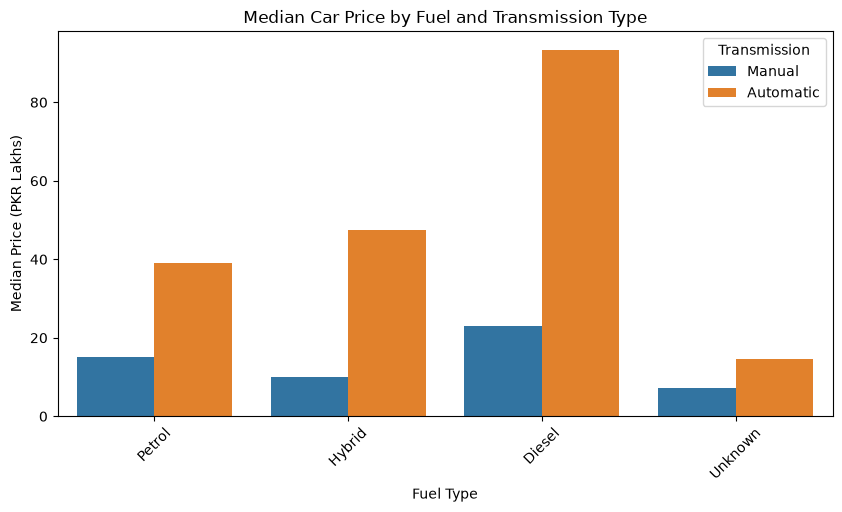

In [21]:
plt.figure(figsize=(10, 5))
sns.barplot(data=df, x="fuel", y="price_lakhs", hue="transmission", estimator="median", errorbar=None)
plt.title("Median Car Price by Fuel and Transmission Type")
plt.xlabel("Fuel Type")
plt.ylabel("Median Price (PKR Lakhs)")
plt.xticks(rotation=45)
plt.legend(title="Transmission")
plt.show()

In [22]:
df.groupby(["fuel", "transmission"])["price_lakhs"].median()

fuel     transmission
Diesel   Automatic       93.425
         Manual          23.000
Hybrid   Automatic       47.500
         Manual           9.975
Petrol   Automatic       39.000
         Manual          15.000
Unknown  Automatic       14.500
         Manual           7.325
Name: price_lakhs, dtype: float64

**Interpretation:**
- **What?** Automatic petrol cars have a median asking price of PKR 39 lakh, compared to PKR 15 lakh for manual petrol cars. Automatic diesel cars have an even higher median of approximately PKR 93.4 lakh.
- **So what?** Asking prices vary considerably across fuel and transmission categories, partly due to differences in vehicle types and specifications.
- **Now what?** Dealerships should compare prices within similar vehicle categories rather than using one pricing strategy for all cars.

### Chart 7: Additional Seaborn chart - Violin plot

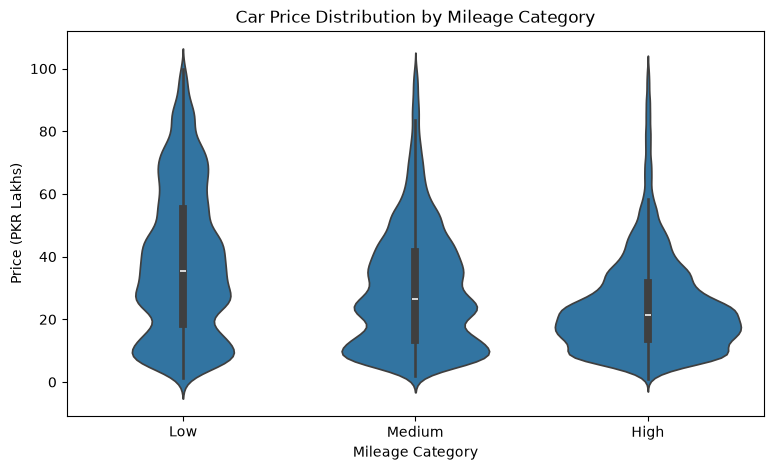

In [23]:
plt.figure(figsize=(9, 5))
sns.violinplot(data=df[df["price_lakhs"] <= 100], x="mileage_category", y="price_lakhs")
plt.title("Car Price Distribution by Mileage Category")
plt.xlabel("Mileage Category")
plt.ylabel("Price (PKR Lakhs)")
plt.show()

In [24]:
df[df["price_lakhs"] <= 100].groupby("mileage_category", observed=True)["price_lakhs"].median()

mileage_category
Low       35.50
Medium    26.40
High      21.25
Name: price_lakhs, dtype: float64

**Interpretation:**
- **What?** Cars with low mileage have the highest median asking price (PKR 35.5 lakh), followed by medium-mileage cars (PKR 26.4 lakh) and high-mileage cars (PKR 21.25 lakh), considering vehicles priced up to PKR 100 lakhs.
- **So what?** Lower-mileage vehicles generally have higher asking prices, suggesting that mileage is an important pricing factor.
- **Now what?** Dealerships should use mileage categories when comparing prices and evaluating vehicles for resale.

### Chart 8: Additional Matplotlib chart - Horizontal bar chart

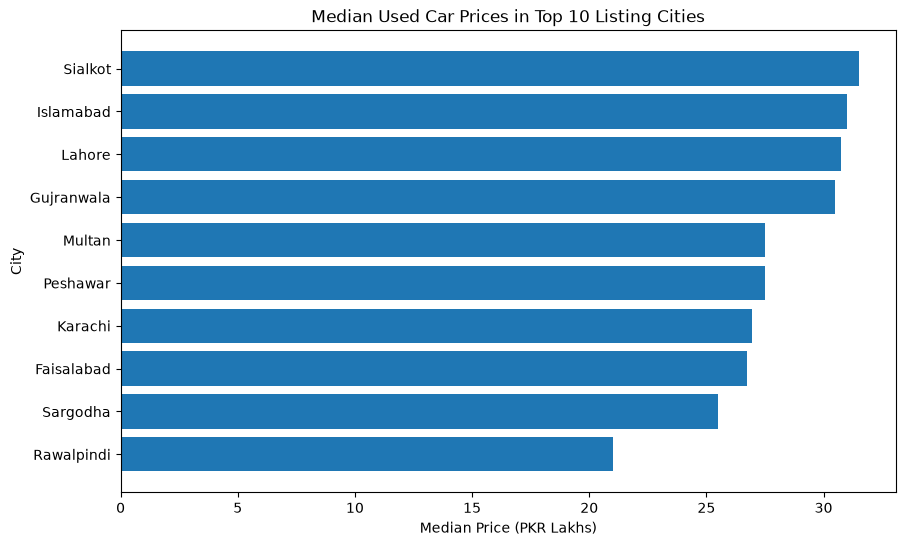

In [25]:
top_cities = df["city"].value_counts().head(10).index

city_prices = df[df["city"].isin(top_cities)].groupby("city")["price_lakhs"].median()
city_prices = city_prices.sort_values()

plt.figure(figsize=(10, 6))
plt.barh(city_prices.index, city_prices.values)
plt.title("Median Used Car Prices in Top 10 Listing Cities")
plt.xlabel("Median Price (PKR Lakhs)")
plt.ylabel("City")
plt.show()

In [26]:
df[df["city"].isin(top_cities)].groupby("city")["price_lakhs"].median().sort_values(ascending=False)

city
Sialkot       31.50
Islamabad     31.00
Lahore        30.75
Gujranwala    30.50
Peshawar      27.50
Multan        27.50
Karachi       26.95
Faisalabad    26.75
Sargodha      25.50
Rawalpindi    21.00
Name: price_lakhs, dtype: float64

**Interpretation:**
- **What?** Among the ten cities with the most listings, Sialkot has the highest median asking price (PKR 31.5 lakh), followed by Islamabad (PKR 31 lakh) and Lahore (PKR 30.75 lakh). Rawalpindi has the lowest median (PKR 21 lakh).
- **So what?** Asking prices vary across cities, possibly because of differences in vehicle types, brands, and age.
- **Now what?** Dealerships should compare local market prices and vehicle characteristics before making purchasing and pricing decisions.

## Part E: Insights and Recommendations

### Key Insights

1. The cleaned dataset contains 72,529 used-car listings, with an overall median asking price of PKR 27 lakh.
2. Toyota (23,217), Suzuki (21,258), and Honda (15,789) are the three most frequently listed brands, showing their strong presence in the dataset.
3. Vehicles manufactured in 2021 have the highest number of listings (6,159), followed by 2022 (5,698).
4. Engine capacity has a moderate positive correlation with asking price (0.51), while vehicle age (-0.28) and mileage (-0.16) have negative correlations.
5. Automatic petrol cars have a higher median asking price (PKR 39 lakh) than manual petrol cars (PKR 15 lakh).
6. Among the ten cities with the most listings, Sialkot has the highest median asking price (PKR 31.5 lakh), while Rawalpindi has the lowest (PKR 21 lakh).

### Recommendations

1. **Improve pricing strategies:** Dealerships should consider vehicle age, mileage, engine capacity, brand, and transmission when setting asking prices.
2. **Plan inventory carefully:** Dealers should monitor frequently listed brands such as Toyota, Suzuki, and Honda, while offering vehicles across different price ranges to accommodate customer budgets.
3. **Use regional market comparisons:** Dealerships should compare prices across cities and account for differences in vehicle characteristics before purchasing or listing used cars.